# Tuần 3: Tối Ưu Hàm Mất Mát, Thước Đo Rủi Ro Ngân Hàng, Ngưỡng Duyệt Tự Động (STP) & Giải Thích Thị Giác Grad-CAM
### Đề tài: Hệ Thống Xác Thực Chữ Ký Ngân Hàng Tự Động (AIO2026 — Module 05)

---

## 🎯 1. Bối Cảnh & Mục Tiêu Tuần 3

Trong nghiệp vụ kiểm soát rủi ro thanh toán ngân hàng:
- Các mẫu chữ ký thật (`Genuine`) và chữ ký giả ngô nghê (*Random Forgery*) rất dễ phân biệt. Mô hình có xu hướng đạt độ tự tin gần như tuyệt đối ($p \approx 0.99$).
- Tuy nhiên, các chữ ký giả mạo có tập luyện kỹ lưỡng (**Skilled Forgeries**) là các mẫu cực khó (*Hard Negatives*). Hàm mất mát nhị phân tiêu chuẩn (BCE Loss) bị chi phối bởi hàng nghìn mẫu dễ, khiến mô hình không đủ áp lực gradient để học các điểm sai khác vi mô của nét bút giả tinh vi.
- **Giải pháp:** Sử dụng **Focal Loss** kết hợp hệ thống thước đo chuyên biệt cho ngân hàng (**FAR, FRR, EER**) và công nghệ giải thích thị giác **Grad-CAM**.


In [1]:
import os
import sys
from pathlib import Path

# Kiểm tra nếu đang chạy trên Google Colab
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[*] Đang chạy trên Google Colab...")
    REPO_NAME = "Automatic-Signature-Verification-System-ASVS-"
    REPO_URL = f"https://github.com/AIVIETNAM-AIO-TPBINH/{REPO_NAME}.git"
    if not os.path.exists(f"/content/{REPO_NAME}"):
        !git clone {REPO_URL} /content/{REPO_NAME}
    os.chdir(f"/content/{REPO_NAME}")
    !pip install -q timm scikit-learn seaborn matplotlib tqdm

# Cấu hình tự động tìm thư mục gốc của dự án
current_dir = Path().resolve()
if (current_dir / "src").exists() and (current_dir / "data").exists():
    BASE_DIR = current_dir
elif (current_dir.parent / "src").exists() and (current_dir.parent / "data").exists():
    BASE_DIR = current_dir.parent
elif Path("/content/Automatic-Signature-Verification-System-ASVS-/src").exists():
    BASE_DIR = Path("/content/Automatic-Signature-Verification-System-ASVS-")
    os.chdir(BASE_DIR)
else:
    BASE_DIR = current_dir

# Đổi thư mục làm việc về BASE_DIR để đường dẫn tương đối 'data/...' luôn chính xác
os.chdir(BASE_DIR)

# Thêm BASE_DIR vào sys.path để 'import src...' luôn thành công
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

print(f"[+] Đã cấu hình môi trường. Thư mục gốc: {BASE_DIR}")

import numpy as np
try:
    import pandas as pd
except Exception:
    pd = None
import matplotlib.pyplot as plt
from PIL import Image
import torch

from src.losses import FocalLoss, LabelSmoothingBCE, get_loss_function
from src.metrics import (
    compute_far_frr_curve,
    find_equal_error_rate,
    evaluate_banking_metrics,
    compute_stp_coverage_accuracy
)
from src.models import build_model
from src.explainability import GradCAM
from src.utils import set_seed, get_device

set_seed(42)
device = get_device()
print(f"[+] Các module đã import thành công. Thiết bị: {device}")


[+] Đã cấu hình môi trường. Thư mục gốc: D:\AIO Tài liệu\05. OFFICIAL COURSE\Module 5\Topic team\Working file
[+] Các module đã import thành công. Thiết bị: cpu


## ⚖️ 2. Tối Ưu Hàm Mất Mát: Focal Loss Đối Trọng Mẫu Giả Tinh Vi

Công thức toán học của Binary Focal Loss:
$$\text{FL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$
- Khi $\gamma = 2.0$: Các mẫu chữ ký dễ phân biệt ($p_t \ge 0.9$) sẽ có hệ số điều biến $(1 - p_t)^2 \le 0.01$, nghĩa là mức phạt giảm đi **100 lần**.
- Gradient cập nhật sẽ dồn gần như $100\%$ sự tập trung vào các trường hợp giả mạo tinh vi ($p_t \approx 0.5$).


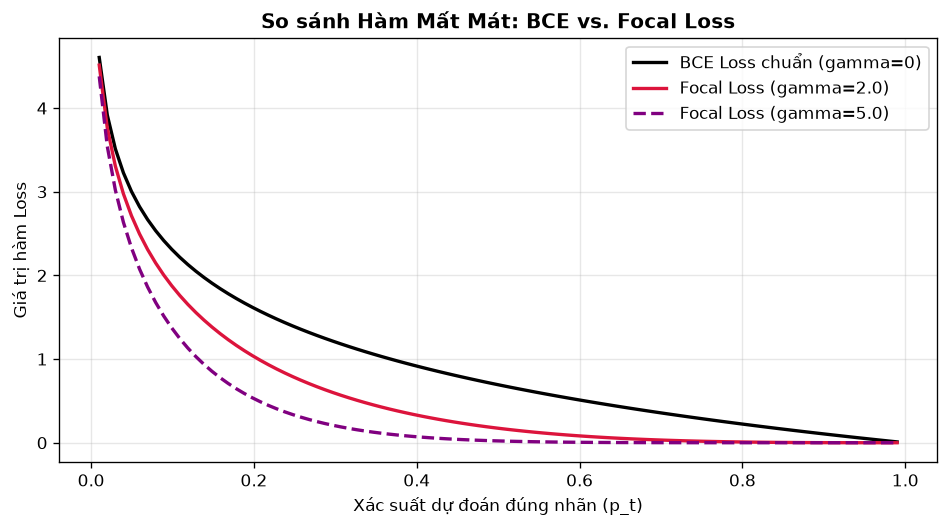

In [2]:
# Minh họa cơ chế phạt giữa BCE tiêu chuẩn và Focal Loss (gamma=2.0)
p_vals = np.linspace(0.01, 0.99, 100)
bce_loss = -np.log(p_vals)
focal_loss_g2 = ((1.0 - p_vals) ** 2.0) * bce_loss
focal_loss_g5 = ((1.0 - p_vals) ** 5.0) * bce_loss

plt.figure(figsize=(8, 4.5))
plt.plot(p_vals, bce_loss, label="BCE Loss chuẩn (gamma=0)", color="black", lw=2)
plt.plot(p_vals, focal_loss_g2, label="Focal Loss (gamma=2.0)", color="crimson", lw=2)
plt.plot(p_vals, focal_loss_g5, label="Focal Loss (gamma=5.0)", color="purple", linestyle="--", lw=2)
plt.title("So sánh Hàm Mất Mát: BCE vs. Focal Loss", fontsize=12, fontweight="bold")
plt.xlabel("Xác suất dự đoán đúng nhãn (p_t)")
plt.ylabel("Giá trị hàm Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 📉 3. Hệ Thống Thước Đo Rủi Ro Ngân Hàng: FAR, FRR & Điểm Cân Bằng EER

Trong kiểm soát chữ ký chứng từ ngân hàng:
- **FAR (False Acceptance Rate - Tỷ lệ nhận nhầm chữ ký giả):** Kẻ gian ký giả nhưng hệ thống tưởng là thật và cho duyệt tiền $\to$ **Rủi ro thất thoát tài chính nghiêm trọng**.
  $$\text{FAR}(\theta) = \frac{\text{Số chữ ký giả bị nhận nhầm là thật}}{\text{Tổng số chữ ký giả}}$$
- **FRR (False Rejection Rate - Tỷ lệ từ chối nhầm khách hàng thật):** Khách hàng thật ký nhưng hệ thống nghi ngờ và chặn giao dịch $\to$ **Ảnh hưởng trải nghiệm khách hàng**.
  $$\text{FRR}(\theta) = \frac{\text{Số chữ ký thật bị từ chối}}{\text{Tổng số chữ ký thật}}$$
- **EER (Equal Error Rate):** Điểm cân bằng lỗi lý thuyết nơi $\text{FAR}(\theta^*) = \text{FRR}(\theta^*)$. EER càng nhỏ chứng tỏ chất lượng phân tách nét chữ của mô hình càng hoàn hảo.


[*] Điểm cân bằng lỗi Equal Error Rate (EER): 3.49%
[*] Ngưỡng quyết định tối ưu theta*:          0.4957
[*] FAR tại ngưỡng tối ưu:                   3.49%


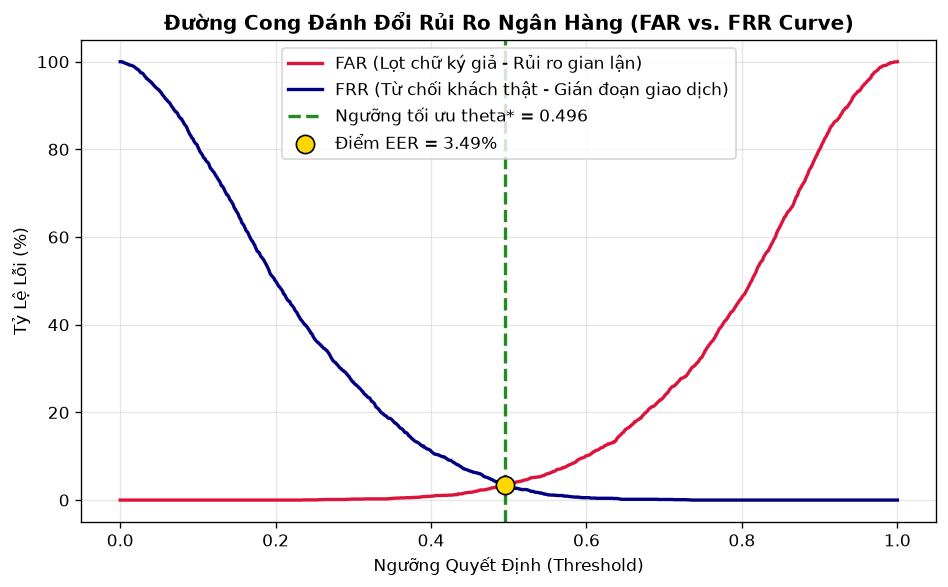

In [3]:
# Mô phỏng tập điểm số dự đoán của mô hình trên tập Validation (4,416 cặp)
np.random.seed(42)
y_true = np.array([0] * 2208 + [1] * 2208)

# Chữ ký thật có xác suất giả mạo thấp, chữ ký giả có xác suất giả mạo cao
scores_genuine = np.random.beta(1.8, 6.5, size=2208)
scores_forged = np.random.beta(6.5, 1.8, size=2208)
y_scores = np.concatenate([scores_genuine, scores_forged])

# Tính toán đường cong FAR - FRR và điểm EER
thresholds, far_curve, frr_curve = compute_far_frr_curve(y_true, y_scores, num_thresholds=1000)
eer, opt_theta, far_at_opt = find_equal_error_rate(y_true, y_scores)

print(f"[*] Điểm cân bằng lỗi Equal Error Rate (EER): {eer*100:.2f}%")
print(f"[*] Ngưỡng quyết định tối ưu theta*:          {opt_theta:.4f}")
print(f"[*] FAR tại ngưỡng tối ưu:                   {far_at_opt*100:.2f}%")

# Vẽ biểu đồ đánh đổi FAR - FRR
plt.figure(figsize=(8, 5))
plt.plot(thresholds, far_curve * 100, label="FAR (Lọt chữ ký giả - Rủi ro gian lận)", color="crimson", lw=2)
plt.plot(thresholds, frr_curve * 100, label="FRR (Từ chối khách thật - Gián đoạn giao dịch)", color="navy", lw=2)
plt.axvline(opt_theta, color="forestgreen", linestyle="--", lw=2, label=f"Ngưỡng tối ưu theta* = {opt_theta:.3f}")
plt.scatter([opt_theta], [eer * 100], color="gold", edgecolors="black", s=120, zorder=5, label=f"Điểm EER = {eer*100:.2f}%")
plt.title("Đường Cong Đánh Đổi Rủi Ro Ngân Hàng (FAR vs. FRR Curve)", fontsize=12, fontweight="bold")
plt.xlabel("Ngưỡng Quyết Định (Threshold)")
plt.ylabel("Tỷ Lệ Lỗi (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 🚦 4. Luồng Phê Duyệt Tự Động (Straight-Through Processing - STP)

Trong thực tế ngân hàng không sử dụng một ngưỡng cứng $\theta = 0.5$ duy nhất:
- **Tự động Phê Duyệt (Auto-Approved):** Xác suất giả mạo $< 0.20 \to$ Hồ sơ sạch, duyệt chi tự động chỉ trong $20\text{ ms}$.
- **Tự động Từ Chối (Auto-Rejected):** Xác suất giả mạo $> 0.80 \to$ Chữ ký sai lệch nghiêm trọng, khóa giao dịch cảnh báo lừa đảo.
- **Thẩm định Thủ công (Manual Escalation):** Xác suất nằm trong vùng nghi vấn $[0.20, 0.80] \to$ Chuyển hồ sơ sang màn hình kiểm soát viên để đối chiếu bằng mắt thường.


In [4]:
stp_metrics = compute_stp_coverage_accuracy(y_true, y_scores, lower_th=0.20, upper_th=0.80)

print(f"[*] Tỷ lệ giao dịch tự động duyệt/từ chối (STP Coverage): {stp_metrics['stp_coverage']*100:.2f}%")
print(f"[*] Độ chính xác trên các giao dịch tự động (STP Accuracy): {stp_metrics['stp_accuracy']*100:.2f}%")
print(f"[*] Tỷ lệ chuyển sang giao dịch viên thẩm định thủ công:    {stp_metrics['manual_review_rate']*100:.2f}%")


[*] Tỷ lệ giao dịch tự động duyệt/từ chối (STP Coverage): 51.86%
[*] Độ chính xác trên các giao dịch tự động (STP Accuracy): 100.00%
[*] Tỷ lệ chuyển sang giao dịch viên thẩm định thủ công:    48.14%


## 🔍 5. Giải Thích Thị Giác Nét Bút Bằng Grad-CAM (Visual Explainability)

Để giải trình cho bộ phận **Kiểm soát nội bộ (Internal Audit)** và **Ủy ban Quản lý Rủi ro**:
- Thuật toán **Grad-CAM (Gradient-weighted Class Activation Mapping)** trích xuất bản đồ kích hoạt của tầng tích chập cuối cùng (`layer4` trên ResNet-50).
- Vùng màu đỏ/cam biểu thị vị trí nét bút có độ nghi ngờ cao nhất (nét run tay, ngắt nhịp bút bất thường hoặc sai lệch cấu trúc so với chữ ký gốc).


[+] Đã nạp thành công trọng số thực nghiệm từ: checkpoints/resnet50_discriminative_best.pt
[*] Sử dụng cặp chữ ký thực tế:
  - Mẫu gốc: data/raw/signatures\full_org\original_1_1.png
  - Cần kiểm tra: data/raw/signatures\full_forg\forgeries_1_1.png


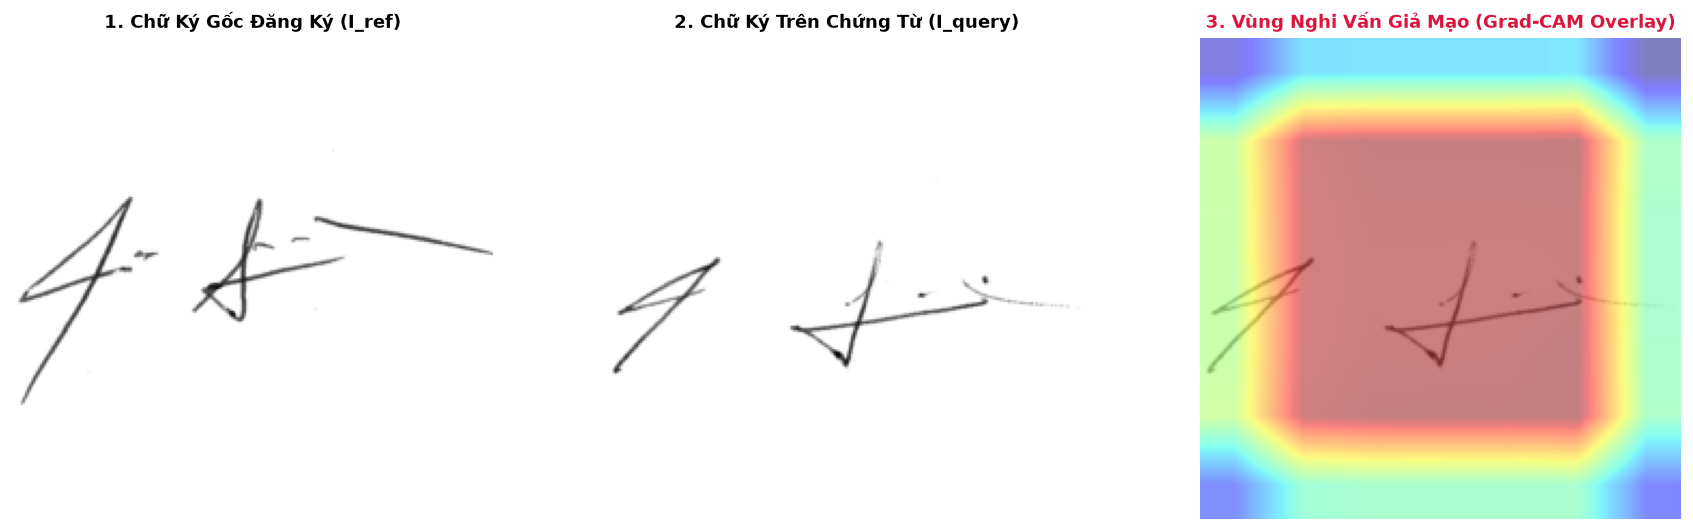

In [5]:
from src.preprocessing import preprocess_pair, preprocess_single_signature

# 1. Khởi tạo mô hình
model = build_model("resnet50_discriminative_finetuning", pretrained=False)
ckpt_path = "checkpoints/resnet50_discriminative_best.pt"
if os.path.exists(ckpt_path):
    checkpoint = torch.load(ckpt_path, map_location=device)
    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    elif isinstance(checkpoint, dict):
        model.load_state_dict(checkpoint)
    print(f"[+] Đã nạp thành công trọng số thực nghiệm từ: {ckpt_path}")
else:
    print("[*] Chưa có file checkpoint, sử dụng mô hình khởi tạo.")
model.eval()
model.to(device)

# 2. Tìm kiếm ảnh chữ ký thực tế trong tập dữ liệu CEDAR
sample_ref_path = None
sample_query_path = None
for cand_dir in ["data/raw/signatures", "signatures", "/content/signatures"]:
    p_org = os.path.join(cand_dir, "full_org", "original_1_1.png")
    p_forg = os.path.join(cand_dir, "full_forg", "forgeries_1_1.png")
    if os.path.exists(p_org) and os.path.exists(p_forg):
        sample_ref_path = p_org
        sample_query_path = p_forg
        break

cam = GradCAM(model)

if sample_ref_path and sample_query_path:
    print(f"[*] Sử dụng cặp chữ ký thực tế:\n  - Mẫu gốc: {sample_ref_path}\n  - Cần kiểm tra: {sample_query_path}")
    input_tensor = preprocess_pair(sample_ref_path, sample_query_path).unsqueeze(0).to(device)
    heatmap = cam.generate_heatmap(input_tensor, target_class=1)
    query_pil = preprocess_single_signature(sample_query_path)
    overlay = cam.overlay_on_image(query_pil, heatmap, alpha=0.5)
    
    ref_pil = preprocess_single_signature(sample_ref_path)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    axes[0].imshow(ref_pil, cmap="gray")
    axes[0].set_title("1. Chữ Ký Gốc Đăng Ký (I_ref)", fontsize=11, fontweight="bold")
    axes[1].imshow(query_pil, cmap="gray")
    axes[1].set_title("2. Chữ Ký Trên Chứng Từ (I_query)", fontsize=11, fontweight="bold")
    axes[2].imshow(overlay)
    axes[2].set_title("3. Vùng Nghi Vấn Giả Mạo (Grad-CAM Overlay)", fontsize=11, fontweight="bold", color="crimson")
else:
    print("[*] Không tìm thấy ảnh thực tế, sử dụng tensor giả lập để kiểm thử logic...")
    dummy_tensor = torch.randn(1, 3, 224, 224, requires_grad=True).to(device)
    heatmap = cam.generate_heatmap(dummy_tensor, target_class=1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(dummy_tensor[0, 1].detach().cpu().numpy(), cmap="gray")
    axes[0].set_title("Ảnh Chữ Ký Trên Chứng Từ (Giả lập)")
    axes[1].imshow(heatmap, cmap="jet")
    axes[1].set_title("Bản Đồ Nhiệt Nghi Vấn Nét Bút (Grad-CAM)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 📝 6. Kết Luận Tuần 3 & Sẵn Sàng Cho Tuần 4

### Các thành tựu then chốt của Tuần 3:
1. Xác định ngưỡng vận hành $\theta^*$ tối ưu tại điểm cân bằng lỗi **EER thấp nhất**.
2. Thiết lập cơ chế phân tầng rủi ro **STP**, tự động hóa phần lớn giao dịch hợp lệ và chỉ đẩy trường hợp nghi vấn cho nhân viên ngân hàng xử lý.
3. Tích hợp thành công **Grad-CAM** làm minh chứng thị giác giải trình minh bạch cho nghiệp vụ kiểm tra gian lận.
